# Vélib’ · Can we predict which stations will be empty or full the next day?

**Paul & Mathéo — classification.** We train on Wednesday, 18 November 2026, and evaluate our predictions for the same stations on Thursday, 19 November. Each row records the state of one station at a particular time. To predict Thursday’s risk, the model only needs the requested hour and the station’s characteristics.

**Running the notebook.** Open this notebook from the repository root with Python 3.10 or later and a Jupyter kernel. Install `pandas`, `numpy`, `matplotlib` and `scikit-learn>=1.2`. Run the cells in order. Once collection is complete, pull the latest data and rerun the notebook. Section 7 explains how to enable the final evaluation.

**Suggested speaking roles.** Mathéo covers data collection, quality checks and hourly patterns. Paul explains the target, features and models. We share the threshold decision, test results and prediction demo.

## 1 · Mathéo — Load the data and check the timestamps

`collected_at` records when GitHub downloaded the CSV. `duedate` records when the source last updated the station’s status. The collector is scheduled to run every 30 minutes. We measure the actual interval between downloads and how old the station reports were when collected. All times are shown in Paris local time.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
                             precision_score, recall_score, roc_auc_score, RocCurveDisplay,
                             PrecisionRecallDisplay)
from sklearn.neighbors import BallTree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ZONE = "Europe/Paris"
WED = "2026-11-18"
THU = "2026-11-19"
raw = pd.read_csv(Path("data/velib_releves.csv"), dtype={"stationcode": "string"})
for col in ["collected_at", "duedate"]:
    raw[col] = pd.to_datetime(raw[col], utc=True, errors="coerce").dt.tz_convert(ZONE)
raw["jour_collecte"] = raw.collected_at.dt.strftime("%Y-%m-%d")
raw["jour_etat"] = raw.duedate.dt.strftime("%Y-%m-%d")
wed_raw = raw.loc[raw.jour_collecte.eq(WED)].copy()
if wed_raw.empty:
    raise ValueError("Aucun téléchargement du mercredi dans data/velib_releves.csv.")
delay = (wed_raw.collected_at - wed_raw.duedate).dt.total_seconds() / 60
audit = wed_raw.assign(retard_min=delay).groupby("collected_at").agg(
    stations=("stationcode", "nunique"), retard_median_min=("retard_min", "median"))
audit["intervalle_min"] = audit.index.to_series().diff().dt.total_seconds() / 60
display(audit.round(1))
print(f"{len(wed_raw):,} lignes brutes · {len(audit)} téléchargements mercredi")

,stations,retard_median_min,intervalle_min
collected_at,,,
2026-11-18 01:13:05+01:00,1526,176.5,NaN
2026-11-18 02:51:10+01:00,1526,34.2,98.1
2026-11-18 03:46:57+01:00,1526,30.0,55.8
2026-11-18 04:51:29+01:00,1526,94.5,64.5
2026-11-18 05:56:46+01:00,1526,279.8,65.3
2026-11-18 06:59:51+01:00,1526,102.5,63.1
2026-11-18 08:17:07+01:00,1526,119.6,77.3
2026-11-18 09:38:31+01:00,1526,201.0,81.4
2026-11-18 10:56:23+01:00,1526,218.6,77.9


32,046 lignes brutes · 21 téléchargements mercredi


## 2 · Paul — Clean the observations and define the target

We use the time of the station update to study hourly patterns. Both the update and the download must fall on the day being analysed. This keeps Thursday’s downloads out of Wednesday’s training data. If several downloads contain the same update for a station, we count it once. We keep installed stations that allow both rentals and returns.

We label a station **empty or full** (`en_tension = 1`) when it has zero bikes available to rent or zero docks available for returns. The latter can also happen when a dock is out of service. We consider alternatives within 300 m later, when prioritising stations for rebalancing.

In [13]:
def prepare_day(frame, day):
    rows = frame.loc[frame.jour_collecte.eq(day)].copy()
    counts = {"téléchargées": len(rows)}
    rows = rows.loc[rows.jour_etat.eq(day) & rows.duedate.le(rows.collected_at)]
    counts["état daté du jour et déjà disponible"] = len(rows)
    flags = ["is_installed", "is_renting", "is_returning"]
    for col in ["capacity", "numbikesavailable", "numdocksavailable"]:
        rows[col] = pd.to_numeric(rows[col], errors="coerce")
    rows = rows.loc[rows[flags].eq("OUI").all(axis=1) & rows.capacity.between(1, 99)
                    & rows.stationcode.notna() & rows.numbikesavailable.ge(0)
                    & rows.numdocksavailable.ge(0)
                    & rows.numbikesavailable.le(rows.capacity)
                    & rows.numdocksavailable.le(rows.capacity)]
    counts["en service, capacité et compteurs valides"] = len(rows)
    rows = rows.sort_values("collected_at").drop_duplicates(["stationcode", "duedate"])
    counts["états distincts"] = len(rows)
    rows["en_tension"] = (rows.numbikesavailable.eq(0) | rows.numdocksavailable.eq(0)).astype(int)
    rows["fill_rate"] = rows.numbikesavailable / rows.capacity
    return rows, pd.Series(counts, name=day)

wed, cleaning = prepare_day(raw, WED)
display(cleaning.to_frame())
print("Part des états en tension le mercredi :", f"{wed.en_tension.mean():.1%}")

,2026-11-18
téléchargées,32046
état daté du jour et déjà disponible,30040
"en service, capacité et compteurs valides",29839
états distincts,26837


Part des états en tension le mercredi : 8.2%


## 3 · Paul — Build the location and time features

We use Wednesday’s first download to build a station catalogue. The coordinates of installed stations give us a fixed set of neighbours for each station. A nearby station may itself run out of bikes. We use the Haversine formula to calculate straight-line distances. Midnight is the reference hour. Model C allows the relationship between distance from Châtelet (Paris 1st) and the log-odds of a station being empty or full to vary by hour.

In [14]:
RAYON_TERRE_KM = 6371.0
CHATELET = np.radians([48.8584, 2.3470])  # point de référence approximatif, place du Châtelet
coords = ["lat", "lon"]
first = wed_raw.loc[wed_raw.collected_at.eq(wed_raw.collected_at.min())].copy()
catalog = first.loc[first.is_installed.eq("OUI")].drop_duplicates("stationcode").copy()
catalog[coords] = catalog.coordonnees_geo.str.split(",", n=1, expand=True).apply(pd.to_numeric, errors="coerce")
catalog = catalog.loc[catalog.lat.between(-90, 90) & catalog.lon.between(-180, 180)].copy()
catalog = catalog.set_index("stationcode", verify_integrity=True)
rad = np.radians(catalog[coords].to_numpy())
tree = BallTree(rad, metric="haversine")
indices, distances = tree.query_radius(rad, r=0.3 / RAYON_TERRE_KM, return_distance=True)
catalog["voisines_300m"] = [
    int(((idx != i) & (dist * RAYON_TERRE_KM < 0.3)).sum())
    for i, (idx, dist) in enumerate(zip(indices, distances))]
delta = rad - CHATELET
h = np.sin(delta[:, 0] / 2)**2 + np.cos(rad[:, 0]) * np.cos(CHATELET[0]) * np.sin(delta[:, 1] / 2)**2
catalog["distance_km"] = 2 * RAYON_TERRE_KM * np.arcsin(np.sqrt(np.clip(h, 0, 1)))
town = catalog.nom_arrondissement_communes.astype("string").str.strip().str.casefold()
catalog["zone"] = town.map(lambda s: "Paris" if s == "paris" else "Banlieue", na_action="ignore")
catalog = catalog.dropna(subset=["zone"])
geo = ["lat", "lon", "distance_km", "voisines_300m", "zone"]
hours = list(range(24))
interactions = [f"dist_h{hr:02}" for hr in hours[1:]]

PLAGES = ["nuit", "pointe_matin", "journee", "pointe_soir", "soiree"]
BORNES = [-1, 6, 9, 16, 19, 23]   # 0-6h, 7-9h, 10-16h, 17-19h, 20-23h
interactions = [f"dist_{p}" for p in PLAGES[1:]]   # "nuit" = référence

def features(rows):
    out = rows.join(catalog[geo], on="stationcode", validate="many_to_one")
    out["heure"] = out.duedate.dt.hour            # gardée pour les graphiques de la section 4
    out["plage"] = pd.cut(out.heure, bins=BORNES, labels=PLAGES).astype(str)
    for p, col in zip(PLAGES[1:], interactions):
        out[col] = out.distance_km * out.plage.eq(p)
    return out
    

def known_stations(rows):
    data = features(rows)
    print("États hors catalogue géographique :", data.zone.isna().sum())
    return data.dropna(subset=geo)

train = known_stations(wed)
print(train.plage.value_counts())
display(train[["name", "duedate", "capacity", "distance_km", "zone", "voisines_300m", "en_tension"]].head())

train = known_stations(wed)
display(train[["name", "duedate", "capacity", "distance_km", "zone", "voisines_300m", "en_tension"]].head())

États hors catalogue géographique : 0
plage
journee         8935
nuit            7458
soiree          4477
pointe_soir     2985
pointe_matin    2982
Name: count, dtype: int64


C:\Users\phden\AppData\Local\Temp\ipykernel_33800\3199269000.py:8: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  catalog = catalog.set_index("stationcode", verify_integrity=True)


,name,duedate,capacity,distance_km,zone,voisines_300m,en_tension
1526,Benjamin Godard - Victor Hugo,2026-11-18 02:17:43+01:00,35,5.281654,Paris,1,0
2547,Temple - Haudriettes,2026-11-18 02:17:32+01:00,19,0.795408,Paris,3,0
2546,Résistance - Parmentier,2026-11-18 02:09:22+01:00,35,6.564002,Banlieue,1,1
2545,Adolphe Lalyre - Armand Silvestre,2026-11-18 02:16:32+01:00,40,7.398183,Banlieue,0,0
2544,Nicolaï - Charenton,2026-11-18 02:17:55+01:00,44,4.215955,Paris,1,0


États hors catalogue géographique : 0


,name,duedate,capacity,distance_km,zone,voisines_300m,en_tension
1526,Benjamin Godard - Victor Hugo,2026-11-18 02:17:43+01:00,35,5.281654,Paris,1,0
2547,Temple - Haudriettes,2026-11-18 02:17:32+01:00,19,0.795408,Paris,3,0
2546,Résistance - Parmentier,2026-11-18 02:09:22+01:00,35,6.564002,Banlieue,1,1
2545,Adolphe Lalyre - Armand Silvestre,2026-11-18 02:16:32+01:00,40,7.398183,Banlieue,0,0
2544,Nicolaï - Charenton,2026-11-18 02:17:55+01:00,44,4.215955,Paris,1,0


## 4 · Mathéo — Explore Wednesday’s hourly patterns

We compare stations in Paris with those in the surrounding suburbs. The data tell us where stations are located. Individual journeys and whether people live or work near a station remain unknown. Each valid station observation counts once towards its hourly average. Gaps in the plot indicate hours with no observations.

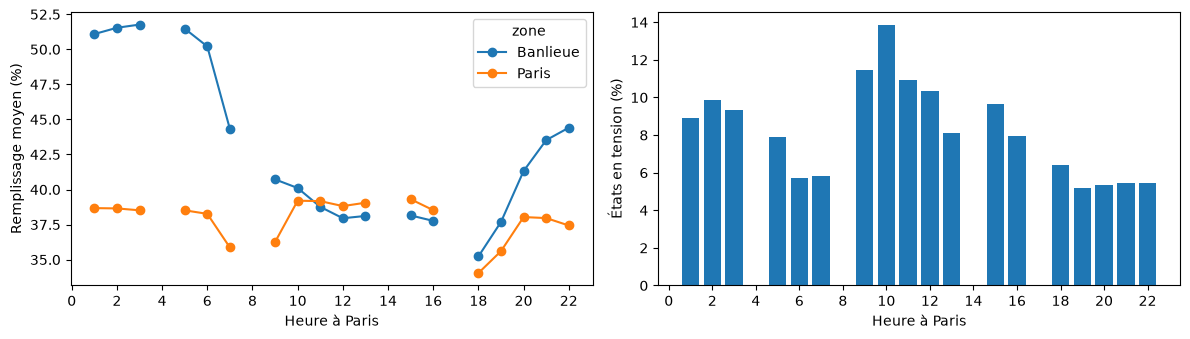

heure,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
zone,,,,,,,,,,,,,,,,,,,,,
Banlieue,NaN,519.0,519.0,519.0,NaN,519.0,519.0,519.0,NaN,518.0,...,NaN,518.0,518.0,NaN,519.0,519.0,519.0,519.0,519.0,NaN
Paris,2.0,972.0,973.0,971.0,1.0,971.0,973.0,972.0,NaN,973.0,...,NaN,971.0,971.0,NaN,974.0,973.0,975.0,973.0,972.0,NaN


heure,1,2,3,5,6,7,9,10,11,12,13,15,16,18,19,20,21,22
proportion en tension,0.089,0.099,0.093,0.079,0.057,0.058,0.115,0.138,0.11,0.103,0.081,0.097,0.079,0.064,0.052,0.054,0.054,0.054
nombre d'états,1491.000,1492.000,1490.000,1490.000,1492.000,1491.000,1491.000,1488.000,1488.00,1492.000,1489.000,1489.000,1489.000,1493.000,1492.000,1494.000,1492.000,1491.000


In [15]:
hours = list(range(24))   # pour l'axe des graphiques uniquement
MIN_OBS = 50              # en dessous, la moyenne d'une heure n'est pas fiable

counts = train.groupby(["heure", "zone"]).size().unstack().reindex(hours)
hourly = train.groupby(["heure", "zone"]).fill_rate.mean().unstack().reindex(hours)
hourly = hourly.where(counts >= MIN_OBS)   # masque les heures avec trop peu d'observations

rate = train.groupby("heure").en_tension.agg(["mean", "size"]).reindex(hours)
rate.loc[rate["size"] < MIN_OBS, "mean"] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
hourly.mul(100).plot(ax=axes[0], marker="o", ylabel="Remplissage moyen (%)", xlabel="Heure à Paris")
axes[1].bar(rate.index, rate["mean"] * 100)
axes[1].set(xlabel="Heure à Paris", ylabel="États en tension (%)")
for ax in axes:
    ax.set_xticks(range(0, 24, 2))
fig.tight_layout()
plt.show()

display(counts.T)   # nombre d'états par heure et par zone
display(rate.dropna().rename(columns={"mean": "proportion en tension", "size": "nombre d'états"}).round(3).T)

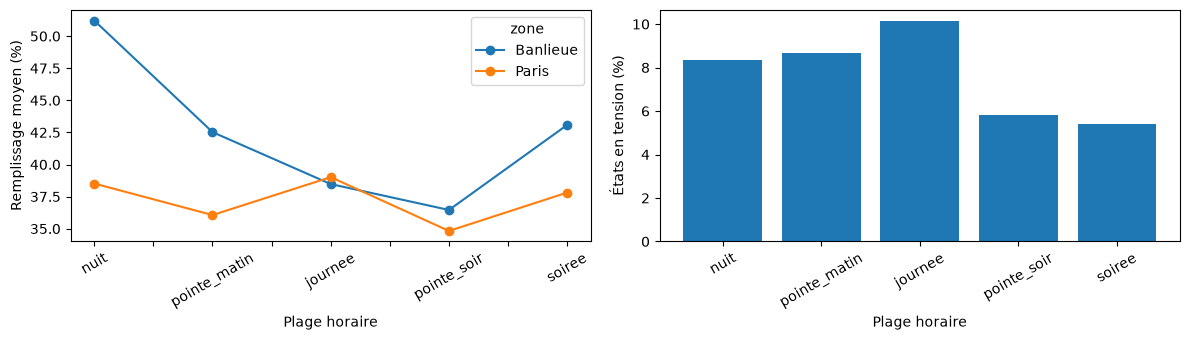

In [16]:
by_plage = (train.groupby(["plage", "zone"]).fill_rate.mean().unstack().reindex(PLAGES))
tension_plage = train.groupby("plage").en_tension.mean().reindex(PLAGES)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
by_plage.mul(100).plot(ax=axes[0], marker="o", ylabel="Remplissage moyen (%)", xlabel="Plage horaire")
axes[1].bar(PLAGES, tension_plage * 100)
axes[1].set(xlabel="Plage horaire", ylabel="États en tension (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

## 5 · Paul — Define the baseline and build pipelines A, B and C

We reserve Thursday for the final test. **Within Wednesday’s data**, we sort the station IDs and hold out every fifth station for validation. This allows the fitting and validation sets to cover the same hours while keeping all records for a given station together. Wednesday’s validation therefore measures how well the model transfers across stations. Thursday’s test measures how well it transfers to the next day.

Model A uses location features and station capacity. Model B adds hour of day as a categorical feature. Model C adds hour-by-distance interactions. The baseline always predicts a normal station. The pipeline learns the scaling parameters during `fit`. We explicitly list the inputs so that the four current availability counts and the fill rate are excluded.

In [17]:
numeric = ["lat", "lon", "distance_km", "capacity", "voisines_300m"]
def make_model(version):
    numbers = numeric + (interactions if version == "C" else [])
    steps = [("num", StandardScaler(), numbers),
             ("zone", OneHotEncoder(categories=[["Banlieue", "Paris"]], drop="first"), ["zone"])]
    if version in ["B", "C"]:
        steps.append(("plage", OneHotEncoder(categories=[PLAGES], drop="first"), ["plage"]))
    return Pipeline([("prep", ColumnTransformer(steps)),
                     ("model", LogisticRegression(max_iter=1000))])

ids = sorted(train.stationcode.unique())
is_val = train.stationcode.isin(ids[::5])
fit, val = train.loc[~is_val], train.loc[is_val]
assert set(fit.stationcode).isdisjoint(val.stationcode)
assert fit.en_tension.nunique() == val.en_tension.nunique() == 2
print(f"Ajustement : {len(fit):,} états · validation : {len(val):,} états")
print(f"Baseline normale : {1 - val.en_tension.mean():.1%} de bonnes réponses, 0 tension détectée.")
print("Plages absentes de l'ajustement :", sorted(set(PLAGES) - set(fit.plage)))

Ajustement : 21,488 états · validation : 5,349 états
Baseline normale : 91.9% de bonnes réponses, 0 tension détectée.
Plages absentes de l'ajustement : []


## 6 · Mathéo — Select the model and alert threshold on the validation set

For this exercise, we assign a cost of two units to a missed event and one unit to a false alert. We can revise this assumption **before** the final evaluation. For each model, we choose the threshold with the lowest validation cost and compare it with the cost of issuing no alerts. If two models tie, we keep the simpler one. We then refit all three pipelines on the full Wednesday dataset and carry the selected model and threshold into Thursday’s test.

In [18]:
COUT_RATE, COUT_FAUSSE_ALERTE = 5, 1
seuils = np.r_[np.arange(101) / 100, np.nextafter(1., 2.)]

def bilan(y, scores, seuil):
    alertes = scores >= seuil
    tn, fp, fn, tp = confusion_matrix(y, alertes, labels=[0, 1]).ravel()
    return {"seuil": seuil, "VN": tn, "FP": fp, "FN": fn, "VP": tp,
            "recall": recall_score(y, alertes, zero_division=0),
            "precision": precision_score(y, alertes, zero_division=0),
            "ROC AUC": roc_auc_score(y, scores) if y.nunique() == 2 else np.nan,
            "PR (AP)": average_precision_score(y, scores) if y.sum() else np.nan,
            "coût": COUT_RATE * fn + COUT_FAUSSE_ALERTE * fp}

def choisir_seuil(y, p):
    target = y.to_numpy(dtype=bool)
    def cout(s):
        positive = p >= s
        return COUT_RATE * (target & ~positive).sum() + COUT_FAUSSE_ALERTE * (~target & positive).sum()
    return min(reversed(seuils), key=cout)  

validation = {}
for version in "ABC":
    pipe = make_model(version).fit(fit, fit.en_tension)
    p = pipe.predict_proba(val)[:, 1]
    validation[version] = bilan(val.en_tension, p, choisir_seuil(val.en_tension, p))
table_val = pd.DataFrame(validation).T
winner = table_val["coût"].idxmin()
display(pd.concat([pd.DataFrame([bilan(val.en_tension, np.zeros(len(val)), 0.5)], index=["Baseline"]), table_val]).round(3))
models = {v: make_model(v).fit(train, train.en_tension) for v in "ABC"}
threshold = validation[winner]["seuil"]
print(f"Modèle logistique retenu : {winner} · seuil : {threshold:.3f}")

,seuil,VN,FP,FN,VP,recall,precision,ROC AUC,PR (AP),coût
Baseline,0.50,4918.0,0.0,431.0,0.0,0.000,0.000,0.500,0.081,2155.0
A,0.14,4698.0,220.0,381.0,50.0,0.116,0.185,0.582,0.116,2125.0
B,0.17,4822.0,96.0,397.0,34.0,0.079,0.262,0.597,0.122,2081.0
C,0.16,4750.0,168.0,384.0,47.0,0.109,0.219,0.597,0.124,2088.0


Modèle logistique retenu : B · seuil : 0.170


VN = True negative
FN = False negative
FP = Fals positvie 
VP = True positive 

recall: 
Out of all actual positive events, what proportion does the model manage to detect ? 

precision:
Among all true positive events, what proportion does the model manage to detect?

ROC AUC
Measures the model's ability to distinguish between positive and negative classes, regardless of the chosen threshold.



### Reading AP and the alert threshold

**Average precision (AP)** is the average of precision across all recall levels. On a chart with recall on the x-axis and precision on the y-axis, each point corresponds to one threshold: it shows the recall and the precision the model reaches at that threshold. Joining the points for all thresholds gives the model's precision–recall curve. Each model (A, B, C) has its own curve, and its AP is the area under that curve. A model with no information gets an AP equal to the share of stations under pressure (0.081 here). A perfect model would get 1.

**The alert threshold** turns a probability into a decision: we raise an alert when a station's predicted probability of being empty or full is greater than or equal to the threshold. A low threshold gives many alerts (high recall, but many false alerts). A high threshold gives few (fewer false alerts, but more missed stations). For each model, we test every threshold from 0.00 to 1.00 on the validation set and compute the cost each time: 5 × missed stations + 1 × false alerts. We keep the threshold with the lowest cost. For model B, this is 0.17, very close to the theoretical threshold of 1 / (1 + 5) ≈ 0.17, which suggests that its probabilities are reasonably calibrated.








## 7 · Paul — Evaluate once on Thursday

Leave `EVALUER_JEUDI` set to `False` while data collection is running. Once Thursday’s CSV is ready and the model and cost assumptions are fixed, set it to `True` and rerun the notebook. Check which hours are covered before reporting the results.

The table compares the three models specified in advance with the baseline. Average precision (AP) summarises the precision–recall curve. Its reference level is the proportion of observations labelled empty or full. The confusion matrix reports decisions at the selected threshold. ROC AUC and AP use the predicted probabilities.

États hors catalogue géographique : 0


,2026-11-19
téléchargées,22890
état daté du jour et déjà disponible,21040
"en service, capacité et compteurs valides",20879
états distincts,15012


Heures de jeudi représentées : [np.int32(0), np.int32(1), np.int32(3), np.int32(6), np.int32(7), np.int32(10), np.int32(11), np.int32(13), np.int32(14), np.int32(16)]
Heures de jeudi absentes de mercredi : [14]
Référence AP : 8.9%


,seuil,VN,FP,FN,VP,recall,precision,ROC AUC,PR (AP),coût
Baseline,0.50,13672.0,0.0,1340.0,0.0,0.000,0.000,0.500,0.089,6700.0
A,0.14,13107.0,565.0,1247.0,93.0,0.069,0.141,0.599,0.118,6800.0
B,0.17,13343.0,329.0,1269.0,71.0,0.053,0.178,0.618,0.131,6674.0
C,0.16,13041.0,631.0,1205.0,135.0,0.101,0.176,0.622,0.135,6656.0


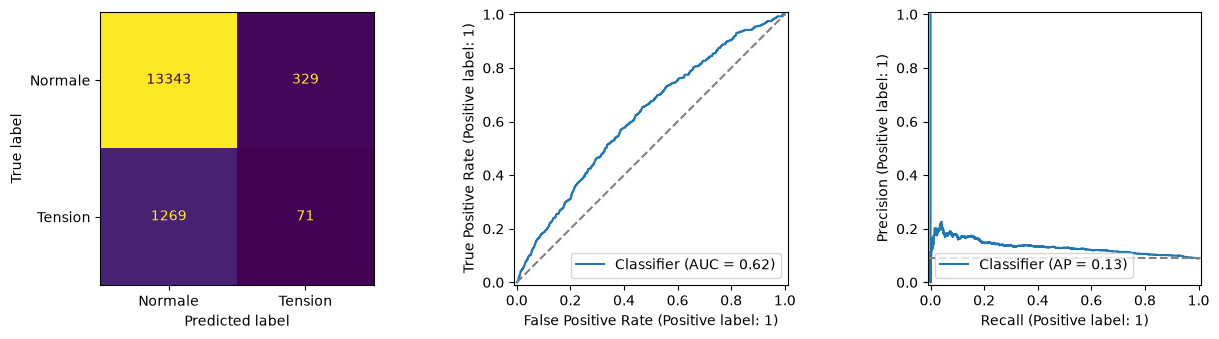

In [19]:
EVALUER_JEUDI = True
if EVALUER_JEUDI:
    thu, counts = prepare_day(raw, THU)
    test = known_stations(thu)
    if test.empty:
        raise ValueError("Aucun état valide de jeudi. Actualiser le CSV avant l’évaluation.")
    assert train.duedate.max() < test.duedate.min()
    display(counts.to_frame())
    print("Heures de jeudi représentées :", sorted(test.heure.unique()))
    print("Heures de jeudi absentes de mercredi :", sorted(set(test.heure) - set(train.heure)))
    print(f"Référence AP : {test.en_tension.mean():.1%}")
    scores = {v: m.predict_proba(test)[:, 1] for v, m in models.items()}
    result = {"Baseline": bilan(test.en_tension, np.zeros(len(test)), 0.5)}
    for v, p in scores.items():
        result[v] = bilan(test.en_tension, p, validation[v]["seuil"])
    display(pd.DataFrame(result).T.round(3))
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
    p = scores[winner]
    ConfusionMatrixDisplay.from_predictions(test.en_tension, p >= threshold, labels=[0, 1],
        display_labels=["Normale", "Tension"], colorbar=False, ax=axes[0])
    if test.en_tension.nunique() == 2:
        RocCurveDisplay.from_predictions(test.en_tension, p, ax=axes[1])
        axes[1].plot([0, 1], [0, 1], "--", color="grey")
        PrecisionRecallDisplay.from_predictions(test.en_tension, p, ax=axes[2])
        axes[2].axhline(test.en_tension.mean(), ls="--", color="grey")
    fig.tight_layout()
    plt.show()
else:
    print("Test du jeudi réservé pour l’évaluation finale.")

## 8 · Paul — Interpret the coefficients and examine the morning–evening pattern

An odds ratio of 1.2 means the **odds**, defined as p/(1−p), are multiplied by 1.2. In model A, a one-unit change in a standardised numerical feature corresponds to one training-set standard deviation. The location category compares Paris with the suburbs. Correlation between geographic features makes their individual effects harder to interpret.

For model C, we convert the distance coefficient and its hourly interaction back to kilometre units and add them to find the effect of one extra kilometre at a given hour. Whether this relationship reverses between morning and evening is an empirical question. Our target groups empty and full stations together. The fill-rate plot helps us see when stations tend to empty or fill up.

In [20]:
prep_a = models["A"].named_steps["prep"]
odds = np.exp(models["A"].named_steps["model"].coef_[0])
display(pd.Series(odds, index=prep_a.get_feature_names_out(), name="odds ratio (A)").round(3))
display(train[numeric].corr().round(2))
pipe_c = models["C"]
prep_c = pipe_c.named_steps["prep"]
coeff = pd.Series(pipe_c.named_steps["model"].coef_[0], index=prep_c.get_feature_names_out())
names = numeric + interactions
scale = pd.Series(prep_c.named_transformers_["num"].scale_, index=names)
base_slope = coeff["num__distance_km"] / scale["distance_km"]
slopes = {hr: base_slope + (coeff[f"num__dist_h{hr:02}"] / scale[f"dist_h{hr:02}"] if hr else 0)
          for hr in sorted(train.heure.unique())}
display(pd.Series(np.exp(pd.Series(slopes)), name="odds ratio pour +1 km à heure fixée (C)").round(3).to_frame().T)

num__lat              0.993
num__lon              0.943
num__distance_km      0.873
num__capacity         0.699
num__voisines_300m    1.106
zone__zone_Paris      1.039
Name: odds ratio (A), dtype: float64

,lat,lon,distance_km,capacity,voisines_300m
lat,1.00,-0.10,-0.15,-0.00,0.15
lon,-0.10,1.00,-0.12,0.02,0.03
distance_km,-0.15,-0.12,1.00,-0.14,-0.69
capacity,-0.00,0.02,-0.14,1.00,0.01
voisines_300m,0.15,0.03,-0.69,0.01,1.00


KeyError: 'num__dist_h01'

## 9 · Mathéo — Run the final pipeline for a future hour

The prediction function takes a requested time and a table of station IDs and known capacities. For each station, it returns a probability and an alert decision. A high-risk station with no neighbour within 300 m deserves particular attention. Where neighbours exist, check whether they can provide the service the rider needs before sending a rebalancing team. Looking at alerts across several hours helps distinguish a one-off event from a recurring priority.

In [ ]:
def predire_stations(stations, heure_prevue):
    rows = stations[["stationcode", "capacity"]].copy()
    rows["stationcode"] = rows.stationcode.astype("string")
    rows["capacity"] = pd.to_numeric(rows.capacity, errors="raise")
    if not rows.capacity.between(1, 99).all():
        raise ValueError("La capacité doit être comprise entre 1 et 99.")
    stamp = pd.Timestamp(heure_prevue)
    rows["duedate"] = stamp.tz_localize(ZONE) if stamp.tzinfo is None else stamp.tz_convert(ZONE)
    x = features(rows)
    if x.zone.isna().any():
        raise ValueError("Station absente du catalogue du mercredi : " +
                         ", ".join(x.loc[x.zone.isna(), "stationcode"].astype(str).unique()))
    out = x[["stationcode", "duedate", "voisines_300m"]].copy()
    out["heure_vue_mercredi"] = x.heure.isin(train.heure.unique())
    out["probabilite"] = models[winner].predict_proba(x)[:, 1]
    out["en_tension_predite"] = out.probabilite.ge(threshold)
    out["alerte_sans_voisine"] = out.en_tension_predite & out.voisines_300m.eq(0)
    return out.sort_values("probabilite", ascending=False)

stations = train.sort_values("collected_at").drop_duplicates("stationcode", keep="last")
heure_demo = min(train.heure.unique(), key=lambda h: (abs(h - 8), h))
print(f"Démonstration du jeudi à {heure_demo:02}:00, heure couverte le mercredi.")
demo = predire_stations(stations, f"{THU} {heure_demo:02}:00")
display(demo.head(8))
planning = pd.concat([predire_stations(stations, f"{THU} {hr:02}:00") for hr in sorted(train.heure.unique())])
priorites = (planning.loc[planning.voisines_300m.eq(0)].groupby("stationcode")
             .agg(heures_en_alerte=("en_tension_predite", "sum"), heures_evaluees=("duedate", "size"),
                  risque_moyen=("probabilite", "mean")).query("heures_en_alerte > 0")
             .sort_values(["heures_en_alerte", "risque_moyen"], ascending=False))
display(priorites.join(catalog["name"]).head(10))

Démonstration du jeudi à 07:00, heure couverte le mercredi.


,stationcode,duedate,voisines_300m,heure_vue_mercredi,probabilite,en_tension_predite,alerte_sans_voisine
31497,2005,2026-11-19 07:00:00+01:00,8,True,0.140510,False,False
31187,10017,2026-11-19 07:00:00+01:00,8,True,0.135679,False,False
31768,6020,2026-11-19 07:00:00+01:00,5,True,0.132274,False,False
31470,1007,2026-11-19 07:00:00+01:00,6,True,0.128186,False,False
31689,10003,2026-11-19 07:00:00+01:00,7,True,0.126365,False,False
31899,5201,2026-11-19 07:00:00+01:00,6,True,0.124846,False,False
31295,4020,2026-11-19 07:00:00+01:00,9,True,0.124830,False,False
30960,10020,2026-11-19 07:00:00+01:00,4,True,0.123698,False,False


,heures_en_alerte,heures_evaluees,risque_moyen,name
stationcode,,,,


## 10 · Paul & Mathéo — Eight checks from the course

1. **Which rows were used to fit the transformations?** During model selection, the pipeline uses only Wednesday’s fitting subset. For Thursday’s predictions, we refit it on all of Wednesday.
2. **What would `score()` return?** For this classifier it returns accuracy. We compute each evaluation metric explicitly.
3. **What type of target is y?** It is binary. We split the final train and test sets by date and hold out stations for internal validation.
4. **Are the features available when we make a prediction?** We know the requested hour, station location and capacity. The availability counts and fill rate are used to construct the target or explore the data.
5. **Which direction do we optimise in?** We minimise the business cost directly. This calculation uses no scikit-learn scorer with a `neg_` prefix.
6. **What does the baseline achieve?** It always predicts a normal station and detects zero empty or full stations. We compare recall, precision and AP, using the event rate as the reference for AP.
7. **Which data determined the threshold?** Wednesday’s validation set determines the model and threshold. Thursday is reserved for the final evaluation.
8. **How should we read the coefficients?** Before interpreting an odds ratio, check the unit, reference category, interactions and correlations between features.

### Oral presentation · 10 minutes

- **1 minute** — Start with the single snapshot from our SQL project and introduce the next-day prediction question.
- **2 minutes** — Define the target and illustrate the two timestamps using one station record.
- **5 minutes** — Show Wednesday’s hourly pattern, compare A, B and C with the baseline, and explain Thursday’s false positives and false negatives.
- **2 minutes** — Demonstrate one prediction and discuss rebalancing priorities. One Wednesday and one Thursday let us compare those two dates. Studying weekday effects and the reasons people travel requires a longer observation period and additional evidence.